# Train a tiny DDPM end to end

Booster LEAP, Diffusion Models, topic 3. You train a small diffusion model on 8 x 8 digit images, generate new digits with it, measure how well it works, and then repeat the recipe on crops of real photographs.

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU. It loads three real photographs from our public GitHub repository (an internet connection is needed, Colab has one). Photos: china.jpg and flower.jpg are scikit-learn sample images (Flickr users danielbuechele and vultilion, CC BY 2.0); grace_hopper.jpg is a U.S. Navy photograph, public domain. Change one thing at a time and run again; the last cell tells you what to try, including your own photo.

**What you need to know first:** nothing about diffusion. Two ideas help: a *Gaussian* is the bell-curve random number (`np.random.standard_normal`), and a *pixel value* is a number from 0 to 255. Everything else is explained where it appears.

## 1. The data: 8 x 8 digits

We train on the 1797 small digit images of scikit-learn. Pixel values 0 to 16 are rescaled to the range -1 to 1, because the noise of a diffusion model has about that size. A separate classifier (the 'judge') is trained on real digits only; later it tells us how digit-like the generated pictures are.

data: (1797, 1, 8, 8)  values from -1.0 to 1.0  the judge recognises 91.9% of real test digits
torch 2.14.0+cpu - runs on the CPU, no GPU needed


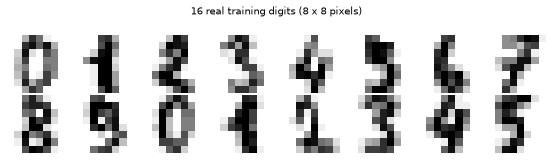

In [ ]:
import math, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

d = load_digits()
X = torch.tensor(d.images, dtype=torch.float32)[:, None] / 16 * 2 - 1          # 1797 digits, 1 channel, 8 x 8, values -1 .. 1
Y = d.target
train_x, test_x = X[:1500], X[1500:]
judge = LogisticRegression(max_iter=2000).fit(train_x.flatten(1).numpy(), Y[:1500])   # a separate classifier, used only to judge generated digits
print("data:", tuple(X.shape), " values from", X.min().item(), "to", X.max().item(), " the judge recognises", f"{100 * judge.score(test_x.flatten(1).numpy(), Y[1500:]):.1f}% of real test digits")

import matplotlib.pyplot as plt
import numpy as np
print("torch", torch.__version__, "- runs on the CPU, no GPU needed")

def grid(imgs, ncols=8, title=None, size=1.0):
    """show a batch of 1 x 8 x 8 images (values -1..1) as a grid"""
    n = len(imgs)
    rows = (n + ncols - 1) // ncols
    fig, ax = plt.subplots(rows, ncols, figsize=(ncols * size, rows * size + 0.3))
    for a, k in zip(np.atleast_1d(ax).ravel(), range(rows * ncols)):
        a.axis("off")
        if k < n:
            a.imshow(imgs[k, 0].numpy(), cmap="gray_r", vmin=-1, vmax=1)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()

grid(train_x[:16], 8, "16 real training digits (8 x 8 pixels)")

## 2. The noise schedule and the closed form (topic 2)

`ab[t]` is the share of signal left after step `t + 1`. The closed form `x_t = sqrt(ab) x0 + sqrt(1 - ab) noise` makes any noisy picture in one line.

signal left: [0.9999, 0.971, 0.659, 0.0786, 0.0]


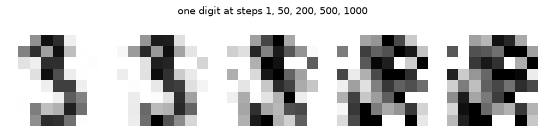

In [ ]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T)              # the linear schedule of topic 2
ab = torch.cumprod(1 - betas, 0)                   # ab[t] = signal left after step t + 1 (t = 0 is the first step)

# the closed form of topic 2 on digits: one clean digit at five steps of the schedule, always the same noise draw
x0 = train_x[3:4]
eps = torch.randn_like(x0, generator=torch.Generator().manual_seed(0)) if False else torch.randn(x0.shape, generator=torch.Generator().manual_seed(0))
steps_shown = [0, 49, 199, 499, 999]
noisy = torch.cat([ab[t].sqrt() * x0 + (1 - ab[t]).sqrt() * eps for t in steps_shown])
grid(noisy.clamp(-1, 1), 5, "one digit at steps " + ", ".join(str(t + 1) for t in steps_shown), size=1.6)
print("signal left:", [round(ab[t].item(), 4) for t in steps_shown])

## 3. The network: a small U-Net

Lesson 3 explained every part. It takes a noisy picture and the step number and returns a picture of the same size: the noise estimate. Here it is as code, with the check that the shapes match and the parameter count.

In [ ]:
def sinusoidal(t, dim=32):                          # time embedding: sines and cosines of the step number
    f = torch.exp(-math.log(1000) * torch.arange(dim // 2) / (dim // 2))
    a = t[:, None].float() * f[None]
    return torch.cat([a.sin(), a.cos()], 1)

class Block(nn.Module):                             # two 3x3 convolutions; the time embedding is added in the middle
    def __init__(self, i, o, td):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(i, o, 3, padding=1), nn.Conv2d(o, o, 3, padding=1)
        self.t = nn.Linear(td, o)
        self.n1, self.n2 = nn.GroupNorm(4, o), nn.GroupNorm(4, o)
    def forward(self, x, e):
        h = F.silu(self.n1(self.c1(x))) + self.t(e)[:, :, None, None]
        return F.silu(self.n2(self.c2(h)))

class UNet(nn.Module):                              # image size must be divisible by 4
    def __init__(self, ch=1, c=16, skip=True, td=64):
        super().__init__()
        self.skip = skip
        self.te = nn.Sequential(nn.Linear(32, td), nn.SiLU(), nn.Linear(td, td))
        self.i = nn.Conv2d(ch, c, 3, padding=1)
        self.d1, self.d2, self.m = Block(c, c, td), Block(c, 2 * c, td), Block(2 * c, 2 * c, td)
        k = 2 if skip else 1                        # with skip connections the up blocks get twice the channels
        self.u2, self.u1 = Block(2 * c * k, c, td), Block(c * k, c, td)
        self.o = nn.Conv2d(c, ch, 1)
    def forward(self, x, t):
        e = self.te(sinusoidal(t))
        h0 = self.d1(self.i(x), e)                  # full size, c channels
        h1 = self.d2(F.avg_pool2d(h0, 2), e)        # half size, 2c channels
        m = self.m(F.avg_pool2d(h1, 2), e)          # quarter size, 2c channels (the bottom of the U)
        u = F.interpolate(m, scale_factor=2)
        u = self.u2(torch.cat([u, h1], 1) if self.skip else u, e)
        u = F.interpolate(u, scale_factor=2)
        u = self.u1(torch.cat([u, h0], 1) if self.skip else u, e)
        return self.o(u)

net_test = UNet(ch=1, c=16)
x = torch.randn(5, 1, 8, 8)
print("input", tuple(x.shape), "-> output", tuple(net_test(x, torch.tensor([10, 100, 300, 600, 900])).shape), " parameters:", sum(p.numel() for p in net_test.parameters()))
print("without skip connections:", sum(p.numel() for p in UNet(ch=1, c=16, skip=False).parameters()), "parameters")

input (5, 1, 8, 8) -> output (5, 1, 8, 8)  parameters: 69697
without skip connections: 62785 parameters


## 4. The training loop

Eight lines: a batch of real digits, a random step for each, fresh noise, the closed form, ask the network for the noise, squared error, update. 2000 updates take a few minutes on a CPU.

parameters: 69697
updates    1 to  500: average loss 0.1563
updates  501 to 1000: average loss 0.1081
updates 1001 to 1500: average loss 0.0976
updates 1501 to 2000: average loss 0.0909


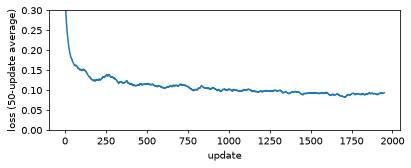

In [ ]:
torch.manual_seed(0)
net = UNet(ch=1, c=16)
print("parameters:", sum(p.numel() for p in net.parameters()))
opt = torch.optim.Adam(net.parameters(), 2e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 2000)
losses = []
for step in range(2000):                               # the training loop: eight lines
    x0 = train_x[torch.randint(0, 1500, (64,))]        # a batch of real digits
    t = torch.randint(0, T, (64,))                     # a random step for every digit
    eps = torch.randn_like(x0)                         # fresh noise: the answer key
    a = ab[t][:, None, None, None]
    loss = F.mse_loss(net(a.sqrt() * x0 + (1 - a).sqrt() * eps, t), eps)     # noise the digits, ask for the noise, squared error
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    losses.append(loss.item())
for k in range(0, 2000, 500):
    print(f"updates {k + 1:4d} to {k + 500:4d}: average loss {sum(losses[k:k + 500]) / 500:.4f}")

fig, ax = plt.subplots(1, 1, figsize=(6, 2.5))
smooth = np.convolve(losses, np.ones(50) / 50, mode="valid")
ax.plot(smooth); ax.set_xlabel("update"); ax.set_ylabel("loss (50-update average)"); ax.set_ylim(0, 0.3)
plt.tight_layout(); plt.show()

## 5. Sampling: from noise to digits

The sampler of lesson 4: start from pure noise and walk back with the network's estimates. `eta = 0` is DDIM, `eta = 1` adds fresh noise at every step (DDPM-style).

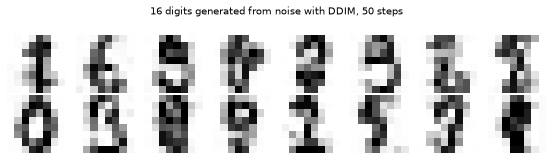

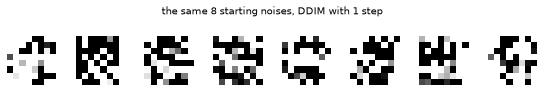

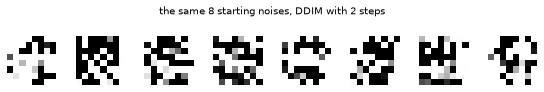

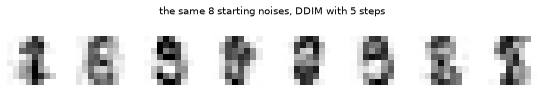

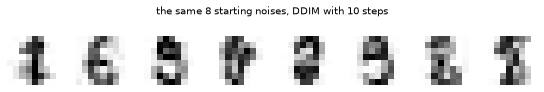

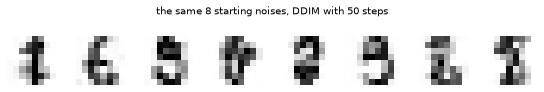

In [ ]:
def sample(n, steps, eta=0.0, seed=0):                 # DDIM (eta = 0) or DDPM-style (eta = 1) sampling, as in lesson 4
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 1, 8, 8, generator=g)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for k, t in enumerate(ts):
        a = ab[t]
        with torch.no_grad():
            e = net(x, torch.full((n,), int(t)))
        x0 = ((x - (1 - a).sqrt() * e) / a.sqrt()).clamp(-1, 1)
        if k + 1 == steps:
            return x0
        ap = ab[ts[k + 1]]
        e = (x - a.sqrt() * x0) / (1 - a).sqrt()
        s = eta * ((1 - ap) / (1 - a)).sqrt() * (1 - a / ap).sqrt()
        x = ap.sqrt() * x0 + (1 - ap - s ** 2).clamp(min=0).sqrt() * e + s * torch.randn(x.shape, generator=g)


grid(sample(16, 50, 0.0, seed=1), 8, "16 digits generated from noise with DDIM, 50 steps")
fig_rows = []
for steps in (1, 2, 5, 10, 50):
    grid(sample(8, steps, 0.0, seed=1), 8, f"the same 8 starting noises, DDIM with {steps} step{'s' if steps > 1 else ''}")

## 6. Does it work? Numbers instead of looking

Three measurements: how confident the judge is (real digits: high, noise: lower), whether all ten digits appear, and how far each generated picture is from its nearest training digit (a copy would be at distance 0; real test digits are about 2.3 from the training digits). Fewer sampling steps should cost quality (lesson 4).

In [ ]:
def report(name, imgs):
    p = torch.tensor(judge.predict_proba(imgs.flatten(1).numpy()))
    near = torch.cdist(imgs.flatten(1), train_x.flatten(1)).min(1).values.mean().item()
    classes = (torch.bincount(p.argmax(1), minlength=10) > 0).sum().item()
    print(f"{name:22s} judge confidence {p.max(1).values.mean().item():.3f}   classes seen {classes:2d} of 10   distance to nearest training digit {near:.2f}")

report("real test digits", test_x[:300])
report("pure noise", torch.randn(300, 1, 8, 8).clamp(-1, 1))
for name, steps, eta in (("DDIM, 100 steps", 100, 0.0), ("DDIM, 50 steps", 50, 0.0), ("DDIM, 10 steps", 10, 0.0), ("DDIM, 5 steps", 5, 0.0), ("DDPM-style, 100 steps", 100, 1.0)):
    report(name, sample(300, steps, eta))

real test digits       judge confidence 0.918   classes seen 10 of 10   distance to nearest training digit 2.34
pure noise             judge confidence 0.680   classes seen 10 of 10   distance to nearest training digit 7.72
DDIM, 100 steps        judge confidence 0.800   classes seen 10 of 10   distance to nearest training digit 2.91
DDIM, 50 steps         judge confidence 0.799   classes seen 10 of 10   distance to nearest training digit 2.88
DDIM, 10 steps         judge confidence 0.780   classes seen 10 of 10   distance to nearest training digit 2.74
DDIM, 5 steps          judge confidence 0.712   classes seen 10 of 10   distance to nearest training digit 2.74
DDPM-style, 100 steps  judge confidence 0.808   classes seen 10 of 10   distance to nearest training digit 2.59


## 7. Part B: the same recipe on photographs

Same eight lines, a U-Net with 3 colour channels and crops of 16 x 16 pixels from two photographs. This is the network behind the figures of lessons 2 to 4.

In [ ]:
# ---- part B: the same recipe on small crops of photographs. The net has 3 colour channels; it is trained on 16 x 16 crops of the flower and the portrait
# and tested on the pagoda photograph, which it never sees (change the three names to try another split).
import io, urllib.request
from PIL import Image
BASE = "https://raw.githubusercontent.com/boosterleap/booster-leap-notebooks/main/diffusion-models/images/"
FILES = {"china": "china.jpg", "flower": "flower.jpg", "hopper": "grace_hopper.jpg"}
def load_photo(name):
    return Image.open(io.BytesIO(urllib.request.urlopen(BASE + FILES[name]).read())).convert("RGB")
def to_tensor(img):
    return torch.tensor(np.asarray(img, dtype=np.float32) / 127.5 - 1).permute(2, 0, 1)

TRAIN_PHOTOS, TEST_PHOTO = ["flower", "hopper"], "china"
# Your own photo (optional): remove the # signs, run the cell, choose a file; it replaces the test photo.
# from google.colab import files
# test_img = Image.open(next(iter(files.upload()))).convert("RGB")
test_img = load_photo(TEST_PHOTO).resize((200, 132), Image.LANCZOS)
train_imgs = [to_tensor(load_photo(n).resize(s, Image.LANCZOS)) for n in TRAIN_PHOTOS for s in ((200, 132), (300, 198))]
test_photo = to_tensor(test_img)[None]
print("training pictures:", [tuple(t.shape) for t in train_imgs], " test picture:", tuple(test_photo.shape))

def crops(n, p=16):
    out = []
    for _ in range(n):
        im = train_imgs[torch.randint(0, len(train_imgs), (1,)).item()]
        y, x = torch.randint(0, im.shape[1] - p + 1, (1,)).item(), torch.randint(0, im.shape[2] - p + 1, (1,)).item()
        out.append(im[:, y:y + p, x:x + p])
    return torch.stack(out)

torch.manual_seed(0)
pnet = UNet(ch=3, c=24)
print("photo net parameters:", sum(p.numel() for p in pnet.parameters()))
opt = torch.optim.Adam(pnet.parameters(), 2e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 1500)
for step in range(1500):                               # the same eight lines
    x0 = crops(48)
    t = torch.randint(0, T, (48,))
    eps = torch.randn_like(x0)
    a = ab[t][:, None, None, None]
    loss = F.mse_loss(pnet(a.sqrt() * x0 + (1 - a).sqrt() * eps, t), eps)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if step % 500 == 499:
        print("update", step + 1, "loss", round(loss.item(), 4))

training pictures: [(3, 132, 200), (3, 198, 300), (3, 132, 200), (3, 198, 300)]  test picture: (1, 3, 132, 200)
photo net parameters: 143363
update 500 loss 0.0314
update 1000 loss 0.0257
update 1500 loss 0.0286


### What can the photo net do?

First as a denoiser (guess of the clean photo from a noisy one at four steps), then as a sampler.

The guess is sharp at low noise and blurs as the noise grows; at step 600 almost nothing of the photo is left to find.


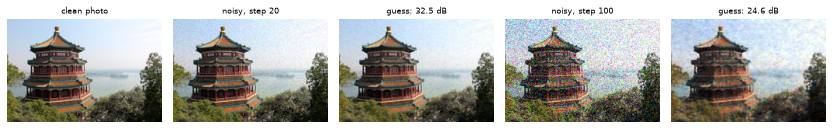

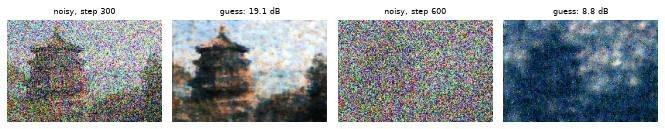

In [ ]:
def show_rgb(imgs, titles, size=2.4):
    fig, ax = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size * 0.7 + 0.4))
    for a, im, ti in zip(np.atleast_1d(ax), imgs, titles):
        a.axis("off"); a.imshow(((im[0] if im.dim() == 4 else im).permute(1, 2, 0).clamp(-1, 1).numpy() + 1) / 2); a.set_title(ti, fontsize=8)
    plt.tight_layout(); plt.show()

def psnr(a, b):
    return 10 * np.log10(4 / F.mse_loss(a, b).item())

g = torch.Generator().manual_seed(5)
eps = torch.randn(test_photo.shape, generator=g)
shown, titles = [test_photo], ["clean photo"]
with torch.no_grad():
    for t in (19, 99, 299, 599):
        a = ab[t]
        xt = a.sqrt() * test_photo + (1 - a).sqrt() * eps
        guess = ((xt - (1 - a).sqrt() * pnet(xt, torch.tensor([t]))) / a.sqrt()).clamp(-1, 1)
        shown += [xt, guess]; titles += [f"noisy, step {t + 1}", f"guess: {psnr(guess, test_photo):.1f} dB"]
show_rgb(shown[:5], titles[:5]); show_rgb(shown[5:], titles[5:])
print("The guess is sharp at low noise and blurs as the noise grows; at step 600 almost nothing of the photo is left to find.")

From pure noise this tiny net makes colourful texture, not objects: it has seen two photographs. Bigger networks and far more pictures are what make real image models.


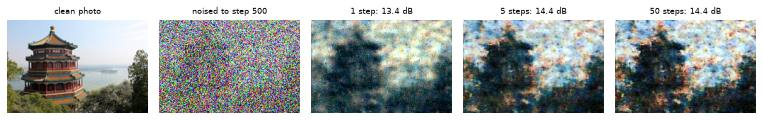

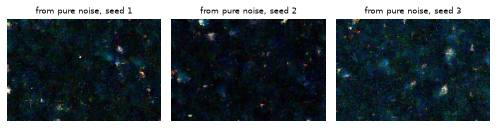

In [ ]:
# walk back from step 500 with k DDIM steps, and generate from pure noise
def ddim_rgb(x, t0, steps):
    ts = torch.linspace(t0, 0, steps).round().long() if steps > 1 else torch.tensor([t0])
    for k, t in enumerate(ts):
        a = ab[t]
        with torch.no_grad():
            e = pnet(x, torch.full((len(x),), int(t)))
        x0 = ((x - (1 - a).sqrt() * e) / a.sqrt()).clamp(-1, 1)
        if k + 1 == len(ts):
            return x0
        ap = ab[ts[k + 1]]
        x = ap.sqrt() * x0 + (1 - ap).sqrt() * ((x - a.sqrt() * x0) / (1 - a).sqrt())

a = ab[499]
start = a.sqrt() * test_photo + (1 - a).sqrt() * eps
outs = [ddim_rgb(start.clone(), 499, k) for k in (1, 5, 50)]
show_rgb([test_photo, start] + outs, ["clean photo", "noised to step 500"] + [f"{k} step{'s' if k > 1 else ''}: {psnr(o, test_photo):.1f} dB" for k, o in zip((1, 5, 50), outs)], size=2.2)
noise_samples = [ddim_rgb(torch.randn(test_photo.shape, generator=torch.Generator().manual_seed(s)), 999, 50) for s in (1, 2, 3)]
show_rgb(noise_samples, [f"from pure noise, seed {s}" for s in (1, 2, 3)])
print("From pure noise this tiny net makes colourful texture, not objects: it has seen two photographs. Bigger networks and far more pictures are what make real image models.")

## Try it yourself

1. In the training cell change `range(2000)` to `range(500)` and `range(4000)` (and the matching `2000` in the scheduler). How do the generated digits change? Which of the three numbers in the report moves most?
2. Change `UNet(ch=1, c=16)` to `c=8` and to `c=32`. Compare the parameter count (cell 'shapes') with the quality of the samples.
3. Build `UNet(ch=1, c=16, skip=False)` and train it the same way. What happens to the samples? (Lesson 3 measured the difference.)
4. Change the number of sampling steps in the last digit cell to 3. Do you still see digits?
5. In part B change `TRAIN_PHOTOS` and `TEST_PHOTO` (for example train on china and hopper, test on flower), or use your own photo. Does the guess at step 100 look better or worse than for the pagoda?
6. Write two sentences for a colleague: what does the network predict during training, and how is a picture made from noise?